In [12]:
import pandas as pd
import csv, io, requests
from dotenv import load_dotenv
import os
from rich.console import Console

In [18]:
load_dotenv()
key= os.getenv('TOKEN2')

In [21]:
from sodapy import Socrata
dataset_id = "nc67-uf89"
batch_size = 50_000
offset = 0
console = Console()



FIELDS = ["plate", "state", "license_type", "summons_number", "issue_date", "violation_time",
          "violation", "judgment_entry_date", "fine_amount", "penalty_amount", "interest_amount",
          "reduction_amount", "payment_amount", "amount_due", "precinct", "county",
          "issuing_agency", "violation_status"]

with Socrata("data.cityofnewyork.us", key, timeout=1200) as client:
    # Get a consistent column order, including fields absent from some batches.
    metadata = client.get_metadata(dataset_id)
    columns = [
        col["fieldName"]
        for col in metadata["columns"]
        if not col["fieldName"].startswith(":")
    ]

    while True:
        rows = client.get(
            dataset_id,
            where = f"issue_date like '%2025%'",
            limit=batch_size,
            offset=offset,
            # order=":id"
          )

        if not rows:
            break

        batch_df = pd.DataFrame.from_records(rows).reindex(columns=columns)

        batch_df.to_csv(
            "socrata_data.csv",
            mode="w" if offset == 0 else "a",
            header=(offset == 0),
            index=False,
        )

        offset += len(rows)
        print(f"Downloaded {offset:,} rows")

Downloaded 50,000 rows
Downloaded 100,000 rows
Downloaded 150,000 rows


ReadTimeout: HTTPSConnectionPool(host='data.cityofnewyork.us', port=443): Read timed out. (read timeout=1200)

In [ ]:
import polars as pl


In [24]:
df = pl.read_csv('socrata_data.csv', infer_schema_length=2000)

In [44]:
df.describe()

statistic,plate,state,license_type,summons_number,issue_date,violation_time,violation,judgment_entry_date,fine_amount,penalty_amount,interest_amount,reduction_amount,payment_amount,amount_due,precinct,county,issuing_agency,violation_status,summons_image
str,str,str,str,f64,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str
"""count""","""150000""","""150000""","""150000""",150000.0,"""150000""","""149994""","""149989""","""23733""",150000.0,150000.0,150000.0,150000.0,150000.0,150000.0,150000.0,"""138789""","""149990""","""25939""","""150000"""
"""null_count""","""0""","""0""","""0""",0.0,"""0""","""6""","""11""","""126267""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""11211""","""10""","""124061""","""0"""
"""mean""",null,null,null,6.8598e9,null,null,null,null,80.39302,11.956667,0.237655,4.247671,88.280937,0.0587334,31.890547,null,null,null,null
"""std""",null,null,null,2.4297e9,null,null,null,null,45.461547,18.196675,0.922359,18.716971,51.712496,2.656515,40.027836,null,null,null,null
"""min""","""0001DPD""","""99""","""999""",1.3223e9,"""01/01/2025""","""00:00A""","""ANGLE PARKING""","""01/01/2026""",25.0,0.0,0.0,0.0,0.0,0.0,0.0,"""BK""","""CON RAIL""","""ADMIN CLAIM GRANTED""","""{'url': 'http://nycserv.nyc.go…"
"""25%""",null,null,null,5.1436e9,null,null,null,null,50.0,0.0,0.0,0.0,50.0,0.0,0.0,null,null,null,null
"""50%""",null,null,null,5.8071e9,null,null,null,null,65.0,0.0,0.0,0.0,75.0,0.0,13.0,null,null,null,null
"""75%""",null,null,null,9.1960e9,null,null,null,null,115.0,25.0,0.0,0.0,115.0,0.0,63.0,null,null,null,null
"""max""","""ZZW615""","""WY""","""VAS""",9.2561e9,"""12/31/2025""","""12:59P""","""WRONG WAY""","""12/25/2025""",650.0,60.0,30.26,525.0,650.0,275.0,170.0,"""ST""","""TRANSIT AUTHORITY""","""HEARING PENDING""","""{'url': 'http://nycserv.nyc.go…"


In [45]:
df.glimpse()

Rows: 150000
Columns: 19
$ plate               <str> 'LLR3725', 'BB61IP', 'KJJ5384', '30607NF', 'M36VMT', '5464214', 'KZF4948', 'KWU8349', 'HKT2504', 'DWD8880'
$ state               <str> 'NY', 'FL', 'NY', 'NY', 'NJ', 'ME', 'NY', 'NY', 'NY', 'NY'
$ license_type        <str> 'PAS', 'PAS', 'PAS', 'COM', 'PAS', 'PAS', 'PAS', 'PAS', 'PAS', 'PAS'
$ summons_number      <i64> 5805753698, 8869397970, 5142975157, 5607290906, 5705595086, 2023606615, 5142975169, 5607291601, 5705595542, 5705595633
$ issue_date          <str> '07/06/2025', '11/20/2025', '08/07/2025', '09/08/2025', '07/24/2025', '04/11/2025', '08/07/2025', '09/08/2025', '07/24/2025', '07/24/2025'
$ violation_time      <str> '03:57P', '06:03A', '03:37P', '03:23P', '04:37P', '02:23P', '03:37P', '04:23P', '05:02P', '05:07P'
$ violation           <str> 'MTA CAMERA VIOLATION - PARKING IN A BUS STOP', 'NO PARKING-DAY/TIME LIMITS', 'FAILURE TO STOP AT RED LIGHT', 'MOBILE BUS LANE VIOLATION', 'MTA CAMERA VIOLATION - DOUBLE PARKING', 'DETACH

In [51]:
df.group_by('issuing_agency').agg(pl.sum('penalty_amount')).sort('penalty_amount', descending=True).limit(10)

issuing_agency,penalty_amount
str,i64
"""TRAFFIC""",968790
"""TRANSIT AUTHORITY""",337290
"""DEPARTMENT OF SANITATION""",193820
"""DEPARTMENT OF TRANSPORTATION""",157550
"""POLICE DEPARTMENT""",106580
"""PARKS DEPARTMENT""",9260
"""NYS PARKS POLICE""",6870
"""NYS COURT OFFICERS""",5160
"""PORT AUTHORITY""",1880


In [57]:
df.select(pl.col('issuing_agency')=="DEPARTMENT OF TRANSPORTATION", pl.col('penalty_amount'))

issuing_agency,penalty_amount
bool,i64
false,25
false,60
true,25
false,25
false,25
…,…
false,0
false,60
false,0


In [99]:
def top_fines(df, state, n=10):
    return (
        df.lazy()
        .filter(pl.col('state') == state)
        .group_by('issuing_agency', 'violation')
        .agg(pl.col('fine_amount').sum(),
             pl.col('violation').count().alias('count'))
        .sort('fine_amount', descending=True)
        .head(n)
        .collect()
    )

top_fines(df, 'FL')


issuing_agency,violation,fine_amount,count
str,str,i64,u32
"""DEPARTMENT OF TRANSPORTATION""","""PHTO SCHOOL ZN SPEED VIOLATION""",28300,566
"""TRANSIT AUTHORITY""","""MTA CAMERA VIOLATION - DOUBLE …",26500,289
"""TRANSIT AUTHORITY""","""MTA CAMERA VIOLATION - PARKING…",26200,305
"""TRAFFIC""","""FIRE HYDRANT""",14835,129
"""TRAFFIC""","""NO STANDING-DAY/TIME LIMITS""",14030,122
"""TRAFFIC""","""NO PARKING-STREET CLEANING""",12350,190
"""TRAFFIC""","""FAIL TO DSPLY MUNI METER RECPT""",9270,210
"""DEPARTMENT OF TRANSPORTATION""","""FAILURE TO STOP AT RED LIGHT""",6800,136
"""TRAFFIC""","""NO STANDING-COMM METER ZONE""",5865,51


In [100]:
by_hour = (
    df.filter(pl.col("violation_time").is_not_null())
    .with_columns(
        hour=(
            pl.col("violation_time").str.slice(0, 2).cast(pl.Int32, strict=False) % 12
            + pl.when(pl.col("violation_time").str.ends_with("P")).then(12).otherwise(0)
        )
    )
    .filter(pl.col("hour").is_between(0, 23))   # drop malformed times
    .group_by("hour")
    .agg(
        total_fines=pl.col("fine_amount").sum(),
        tickets=pl.len(),
    )
    .sort("hour")
)

by_hour.sort("total_fines", descending=True).head(1)  # the peak hour


hour,total_fines,tickets
i32,i64,u32
11,1017985,13013


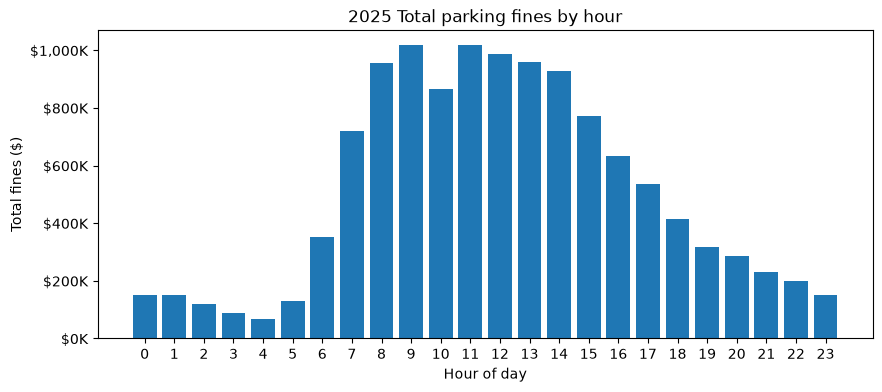

In [104]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_hour["hour"], by_hour["total_fines"])
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Total fines ($)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y/1_000:,.0f}K"))
ax.set_title("2025 Total parking fines by hour")
plt.show()


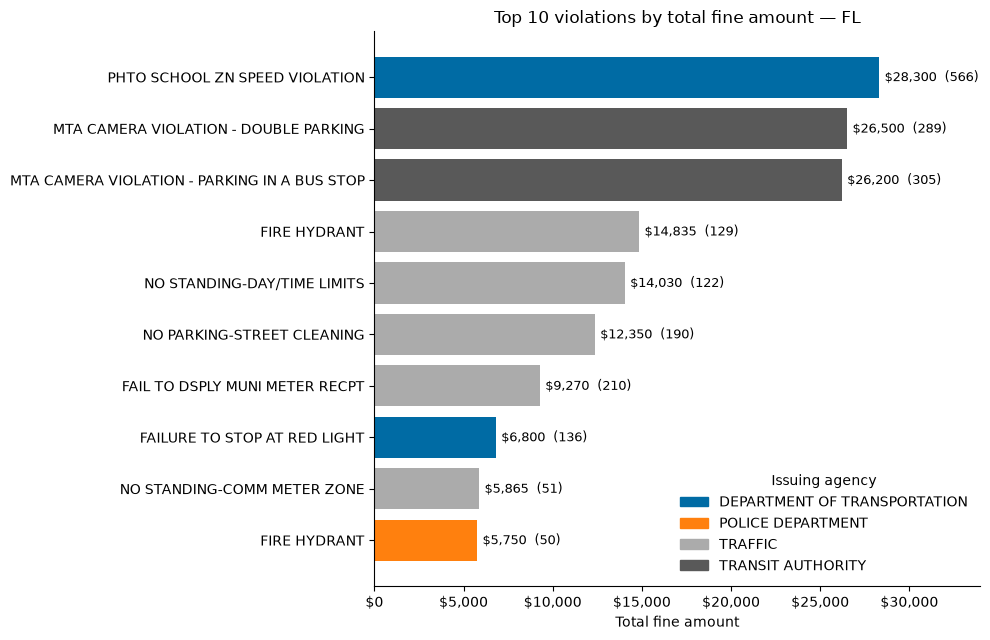

In [106]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter
from matplotlib import style

def plot_top_fines(df, state, n=10):
    data = top_fines(df, state, n).sort('fine_amount')  # ascending, so the largest bar is on top

    agencies = sorted(data['issuing_agency'].unique().to_list())
    cb10 = style.library['tableau-colorblind10']['axes.prop_cycle'].by_key()['color']
    color = {a: cb10[i % len(cb10)] for i, a in enumerate(agencies)}

    fig, ax = plt.subplots(figsize=(10, 0.5 * data.height + 1.5))
    y = range(data.height)  # numeric positions keep repeated violations as separate bars
    bars = ax.barh(y, data['fine_amount'],
                   color=[color[a] for a in data['issuing_agency']])

    ax.set_yticks(y, data['violation'].to_list())
    ax.bar_label(bars, labels=[f'${v:,.0f}  ({c:,})' for v, c in
                               zip(data['fine_amount'], data['count'])],
                 padding=4, fontsize=9)
    ax.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
    ax.margins(x=0.2)  # leave room for the bar labels
    ax.spines[['top', 'right']].set_visible(False)

    ax.legend(handles=[Patch(color=color[a], label=a) for a in agencies],
              title='Issuing agency', loc='lower right', frameon=False)
    ax.set_title(f'Top {n} violations by total fine amount — {state}')
    ax.set_xlabel('Total fine amount')
    plt.tight_layout()
    plt.show()

plot_top_fines(df, 'FL')
